# Análise Exploratória - Olist (E-commerce)

Notebook da etapa 2 do pipeline: **Data Warehouse (Pentaho) → Python (EDA) → Power BI**.

**Fonte:** modelo estrela `dw_olist` no PostgreSQL (`fato_vendas` + dimensões).
**Granularidade da fato:** 1 linha = 1 item de pedido.

Pergunta de negócio: **atrasos na entrega afetam a satisfação do cliente e a receita?**

## 1. Conexão com o Data Warehouse

In [1]:
# Instalar uma vez (no terminal):
# pip install pandas numpy sqlalchemy psycopg2-binary matplotlib seaborn jupyter
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

SENHA = "SUA SENHA"  # senha do usuário postgres

url = URL.create(
    "postgresql+psycopg2",
    username="postgres", password=SENHA,
    host="localhost", port=5432, database="dw_olist",
)
engine = create_engine(url)

In [2]:
# Funções de formatação (padrão brasileiro) usadas nas interpretações
def fmt_n(x):
    return f"{x:,.0f}".replace(",", ".")

def fmt_d(x, casas=2):
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def fmt_p(x):
    return fmt_d(x * 100, 1) + "%"

## 2. Carga dos dados
Os dados vêm do DW já integrados: a fato é unida às dimensões por chaves substitutas (`sk_*`).
A dimensão tempo é usada pela data de compra.

In [3]:
query = """
SELECT
    f.order_id, f.order_item_id, f.status_pedido,
    f.preco, f.valor_frete, f.valor_total,
    f.dias_entrega, f.dias_atraso, f.atrasou, f.nota_avaliacao,
    t.data AS data_compra, t.ano, t.mes, t.ano_mes,
    c.estado AS estado_cliente,
    COALESCE(p.categoria_en, p.categoria, 'sem_categoria') AS categoria,
    p.peso_g,
    v.estado AS estado_vendedor
FROM dw.fato_vendas f
JOIN dw.dim_tempo    t ON t.sk_tempo    = f.sk_tempo_compra
JOIN dw.dim_cliente  c ON c.sk_cliente  = f.sk_cliente
JOIN dw.dim_produto  p ON p.sk_produto  = f.sk_produto
JOIN dw.dim_vendedor v ON v.sk_vendedor = f.sk_vendedor
"""
df = pd.read_sql(query, engine)
print(df.shape)
df.head()

(112650, 18)


,order_id,order_item_id,status_pedido,preco,valor_frete,valor_total,dias_entrega,dias_atraso,atrasou,nota_avaliacao,data_compra,ano,mes,ano_mes,estado_cliente,categoria,peso_g,estado_vendedor
0,00010242fe8c5a6d1ba2dd792cb16214,1,delivered,59.00,13.00,72.00,7.00,-9.00,0.00,5.00,2017-09-13,2017,9,2017-09,RJ,cool_stuff,650.00,SP
1,00018f77f2f0320c557190d7a144bdd3,1,delivered,240.00,20.00,260.00,16.00,-3.00,0.00,4.00,2017-04-26,2017,4,2017-04,SP,pet_shop,"30,000.00",SP
2,000229ec398224ef6ca0657da4fc703e,1,delivered,199.00,18.00,217.00,8.00,-14.00,0.00,5.00,2018-01-14,2018,1,2018-01,MG,furniture_decor,"3,050.00",MG
3,00024acbcdf0a6daa1e931b038114c75,1,delivered,13.00,13.00,26.00,6.00,-6.00,0.00,4.00,2018-08-08,2018,8,2018-08,SP,perfumery,200.00,SP
4,00048cc3ae777c65dbb7d2a0634bc1ea,1,delivered,22.00,13.00,35.00,7.00,-15.00,0.00,4.00,2017-05-15,2017,5,2017-05,MG,housewares,450.00,SP


## 3. Visão geral e qualidade dos dados

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 18 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         112650 non-null  str    
 1   order_item_id    112650 non-null  int64  
 2   status_pedido    112650 non-null  str    
 3   preco            112650 non-null  float64
 4   valor_frete      112650 non-null  float64
 5   valor_total      112650 non-null  float64
 6   dias_entrega     110196 non-null  float64
 7   dias_atraso      110196 non-null  float64
 8   atrasou          110196 non-null  float64
 9   nota_avaliacao   111708 non-null  float64
 10  data_compra      112650 non-null  object 
 11  ano              112650 non-null  int64  
 12  mes              112650 non-null  int64  
 13  ano_mes          112650 non-null  str    
 14  estado_cliente   112650 non-null  str    
 15  categoria        112650 non-null  str    
 16  peso_g           112632 non-null  float64
 17  es

In [5]:
nulos = df.isna().sum().to_frame("nulos")
nulos["%"] = nulos["nulos"] / len(df) * 100
nulos[nulos["nulos"] > 0]

,nulos,%
dias_entrega,2454,2.18
dias_atraso,2454,2.18
atrasou,2454,2.18
nota_avaliacao,942,0.84
peso_g,18,0.02


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_item_id,"112,650.00",1.20,0.71,1.00,1.00,1.00,1.00,21.00
preco,"112,650.00",120.69,183.63,1.00,40.00,75.00,135.00,"6,735.00"
valor_frete,"112,650.00",19.98,15.81,0.00,13.00,16.00,21.00,410.00
valor_total,"112,650.00",140.67,190.73,6.00,55.00,92.00,158.00,"6,929.00"
dias_entrega,"110,196.00",12.41,9.46,0.00,7.00,10.00,16.00,210.00
dias_atraso,"110,196.00",-12.03,10.16,-147.00,-17.00,-13.00,-7.00,188.00
atrasou,"110,196.00",0.07,0.25,0.00,0.00,0.00,0.00,1.00
nota_avaliacao,"111,708.00",4.03,1.39,1.00,4.00,5.00,5.00,5.00
ano,"112,650.00","2,017.54",0.50,"2,016.00","2,017.00","2,018.00","2,018.00","2,018.00"
mes,"112,650.00",6.03,3.23,1.00,3.00,6.00,8.00,12.00


## 4. Tratamento de dados e decisões

Cada decisão abaixo é justificada, porque afeta as métricas do dashboard.

In [7]:
# 4.1 Duplicatas na granularidade (order_id + order_item_id)
print("Duplicatas:", df.duplicated(["order_id", "order_item_id"]).sum())

Duplicatas: 0


In [8]:
# 4.2 Nulos em dias_entrega: são pedidos ainda não entregues?
sem_entrega = df[df["dias_entrega"].isna()]
print(f"Itens sem data de entrega: {len(sem_entrega)} ({len(sem_entrega)/len(df):.1%})")
sem_entrega["status_pedido"].value_counts()

Itens sem data de entrega: 2454 (2.2%)


status_pedido
shipped        1185
canceled        535
invoiced        359
processing      357
delivered         8
unavailable       7
approved          3
Name: count, dtype: int64

In [9]:
# 4.3 Valores inconsistentes
print("Dias de entrega negativos:", (df["dias_entrega"] < 0).sum())
print("Preço <= 0:", (df["preco"] <= 0).sum())
print("Itens sem nota de avaliação:", df["nota_avaliacao"].isna().sum())

Dias de entrega negativos: 0
Preço <= 0: 0
Itens sem nota de avaliação: 942


In [10]:
# Subconjuntos usados nas métricas
df_valido = df[~df["status_pedido"].isin(["canceled", "unavailable"])].copy()   # receita
df_ent    = df[df["dias_entrega"].notna()].copy()                              # prazo de entrega
pedidos   = df_ent.drop_duplicates("order_id").copy()                          # 1 linha por pedido
print(len(df_valido), len(df_ent), len(pedidos))

112101 110196 96476


In [11]:
# Interpretação do tratamento (números calculados a partir dos dados)
total = len(df)
dup = int(df.duplicated(["order_id", "order_item_id"]).sum())
n_canc = int(df["status_pedido"].isin(["canceled", "unavailable"]).sum())
n_sem = int(df["dias_entrega"].isna().sum())
status_sem = ", ".join(f"{k} ({v})" for k, v in sem_entrega["status_pedido"].value_counts().head(3).items())
n_sem_nota = int(df["nota_avaliacao"].isna().sum())
neg = int((df["dias_entrega"] < 0).sum())

if dup == 0:
    dup_txt = "o teste não encontrou duplicatas na granularidade (order_id + order_item_id), então não foi preciso remover registros."
else:
    dup_txt = f"foram encontradas {fmt_n(dup)} duplicatas na granularidade (order_id + order_item_id), que precisam ser revisadas."
if neg == 0:
    neg_txt = "não há prazos de entrega negativos."
else:
    neg_txt = f"há {fmt_n(neg)} itens com prazo de entrega negativo, que devem ser investigados."

display(Markdown(f"""**Decisões de tratamento e seus números:**

- **Pedidos cancelados e indisponíveis** ({fmt_n(n_canc)} itens, {fmt_p(n_canc/total)} da base) ficam fora da receita, pois não geram venda efetiva.
- **Itens sem data de entrega** ({fmt_n(n_sem)} itens, {fmt_p(n_sem/total)}) ficam fora das métricas de prazo, mas permanecem na base de vendas. Os status mais comuns entre eles são: {status_sem}.
- **Notas de avaliação ausentes** ({fmt_n(n_sem_nota)} itens, {fmt_p(n_sem_nota/total)}) não foram preenchidas: inventar uma nota distorceria a satisfação real do cliente.
- **Duplicatas:** {dup_txt}
- **Consistência:** {neg_txt}"""))

**Decisões de tratamento e seus números:**

- **Pedidos cancelados e indisponíveis** (549 itens, 0,5% da base) ficam fora da receita, pois não geram venda efetiva.
- **Itens sem data de entrega** (2.454 itens, 2,2%) ficam fora das métricas de prazo, mas permanecem na base de vendas. Os status mais comuns entre eles são: shipped (1185), canceled (535), invoiced (359).
- **Notas de avaliação ausentes** (942 itens, 0,8%) não foram preenchidas: inventar uma nota distorceria a satisfação real do cliente.
- **Duplicatas:** o teste não encontrou duplicatas na granularidade (order_id + order_item_id), então não foi preciso remover registros.
- **Consistência:** não há prazos de entrega negativos.

## 5. Distribuições

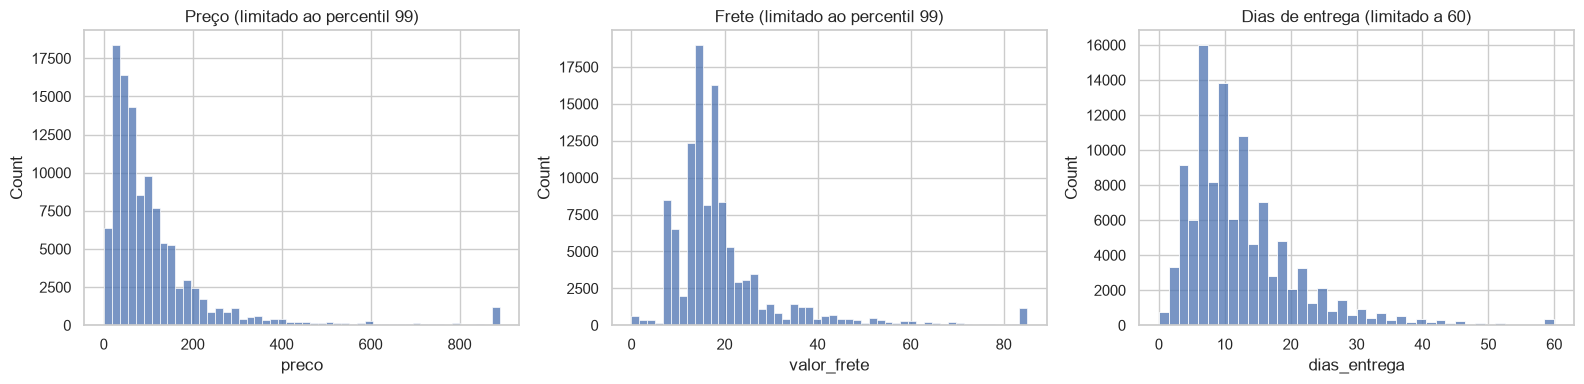

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["preco"].clip(upper=df["preco"].quantile(0.99)), bins=50, ax=ax[0])
ax[0].set_title("Preço (limitado ao percentil 99)")
sns.histplot(df["valor_frete"].clip(upper=df["valor_frete"].quantile(0.99)), bins=50, ax=ax[1])
ax[1].set_title("Frete (limitado ao percentil 99)")
sns.histplot(df_ent["dias_entrega"].clip(upper=60), bins=40, ax=ax[2])
ax[2].set_title("Dias de entrega (limitado a 60)")
plt.tight_layout(); plt.show()

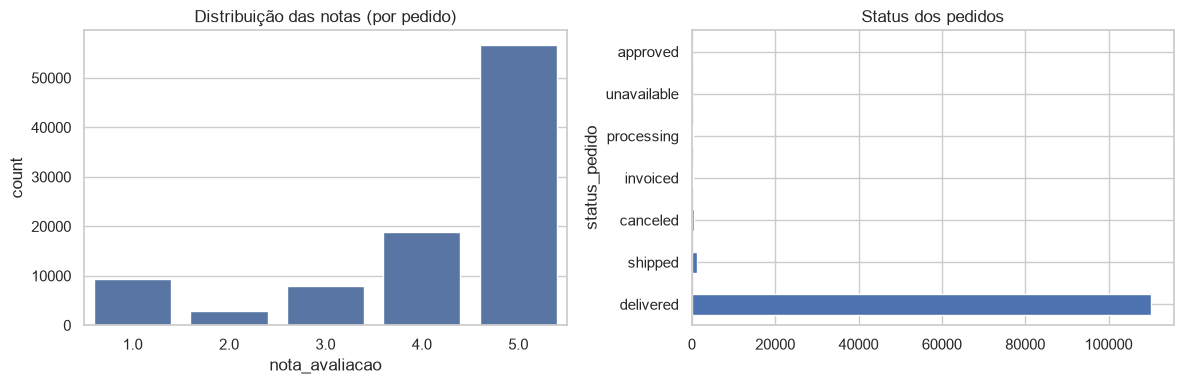

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="nota_avaliacao", data=pedidos, ax=ax[0])
ax[0].set_title("Distribuição das notas (por pedido)")
df["status_pedido"].value_counts().plot(kind="barh", ax=ax[1])
ax[1].set_title("Status dos pedidos")
plt.tight_layout(); plt.show()

In [14]:
# Interpretação das distribuições (números calculados a partir dos dados)
pr = df["preco"]
fr = df["valor_frete"]
de = df_ent["dias_entrega"]
pct5 = (pedidos["nota_avaliacao"] == 5).mean()
pct1 = (pedidos["nota_avaliacao"] == 1).mean()

if pr.mean() > pr.median():
    forma_preco = "assimétrica à direita (a média é maior que a mediana)"
    resto_preco = " A maior parte dos itens tem valor baixo e poucos itens caros puxam a média."
else:
    forma_preco = "sem assimetria forte à direita"
    resto_preco = ""

display(Markdown(f"""**O que as distribuições mostram:**

- **Preço:** distribuição {forma_preco}: média de R$ {fmt_d(pr.mean())} e mediana de R$ {fmt_d(pr.median())}, com máximo de R$ {fmt_d(pr.max())}.{resto_preco}
- **Frete:** mediana de R$ {fmt_d(fr.median())} e média de R$ {fmt_d(fr.mean())}.
- **Prazo de entrega:** mediana de {fmt_d(de.median(), 0)} dias e média de {fmt_d(de.mean(), 1)} dias. 90% das entregas foram concluídas em até {fmt_d(de.quantile(0.9), 0)} dias, e o maior prazo chega a {fmt_d(de.max(), 0)} dias.
- **Notas:** {fmt_p(pct5)} dos pedidos têm nota 5 e {fmt_p(pct1)} têm nota 1. Os dois extremos somam {fmt_p(pct5 + pct1)} das avaliações."""))

**O que as distribuições mostram:**

- **Preço:** distribuição assimétrica à direita (a média é maior que a mediana): média de R$ 120,69 e mediana de R$ 75,00, com máximo de R$ 6.735,00. A maior parte dos itens tem valor baixo e poucos itens caros puxam a média.
- **Frete:** mediana de R$ 16,00 e média de R$ 19,98.
- **Prazo de entrega:** mediana de 10 dias e média de 12,4 dias. 90% das entregas foram concluídas em até 23 dias, e o maior prazo chega a 210 dias.
- **Notas:** 58,8% dos pedidos têm nota 5 e 9,7% têm nota 1. Os dois extremos somam 68,5% das avaliações.

## 6. Outliers (método IQR)

In [15]:
def limites_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["preco", "valor_frete", "dias_entrega"]:
    s = df[col].dropna()
    lo, hi = limites_iqr(s)
    n = ((s < lo) | (s > hi)).sum()
    print(f"{col:13s} limite superior: {hi:10,.2f} | outliers: {n:6d} ({n/len(s):.1%})")

preco         limite superior:     277.50 | outliers:   8423 (7.5%)
valor_frete   limite superior:      33.00 | outliers:  11998 (10.7%)
dias_entrega  limite superior:      29.50 | outliers:   5239 (4.8%)


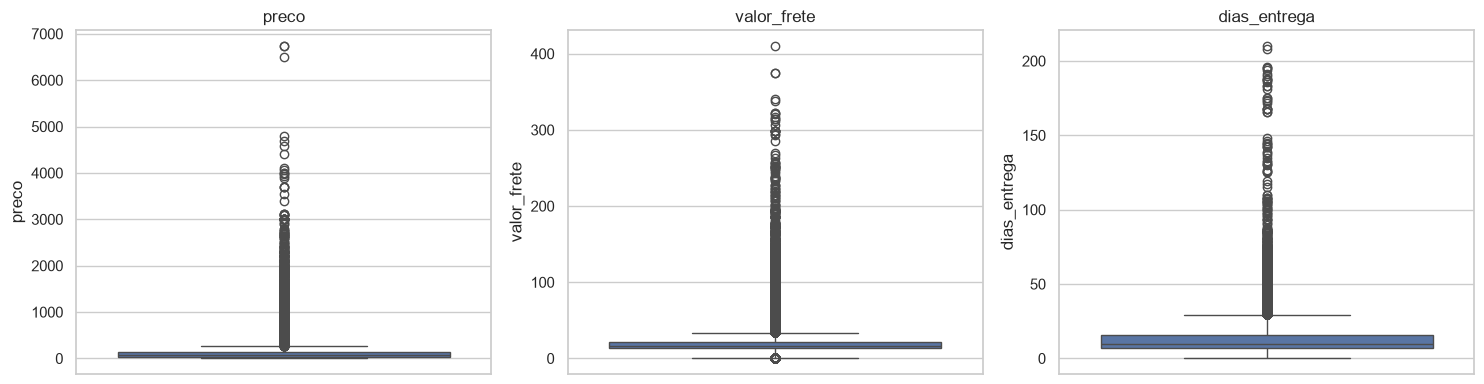

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["preco", "valor_frete", "dias_entrega"]):
    sns.boxplot(y=df[col].dropna(), ax=a); a.set_title(col)
plt.tight_layout(); plt.show()

In [17]:
lo, hi = limites_iqr(df["preco"])
df["outlier_preco"] = df["preco"] > hi   # sinalizado, não removido
df["outlier_preco"].mean()

np.float64(0.07477141588992454)

In [18]:
# Interpretação dos outliers (números calculados a partir dos dados)
linhas = []
for col, nome in [("preco", "preço"), ("valor_frete", "frete"), ("dias_entrega", "dias de entrega")]:
    s = df[col].dropna()
    lim_inf, lim_sup = limites_iqr(s)
    qtd = int(((s < lim_inf) | (s > lim_sup)).sum())
    linhas.append(f"- **{nome}:** {fmt_n(qtd)} outliers ({fmt_p(qtd / len(s))}), com limite superior de {fmt_d(lim_sup)}.")
lista_outliers = "\n".join(linhas)

display(Markdown(f"""**Decisão sobre outliers:**

{lista_outliers}

Decidi **mantê-los**: preços altos (como eletrodomésticos) e entregas muito longas são valores reais do negócio, e removê-los distorceria receita e prazo. Os outliers de preço foram apenas **sinalizados** na coluna `outlier_preco`, e nos gráficos usei o percentil 99 somente para visualização."""))

**Decisão sobre outliers:**

- **preço:** 8.423 outliers (7,5%), com limite superior de 277,50.
- **frete:** 11.998 outliers (10,7%), com limite superior de 33,00.
- **dias de entrega:** 5.239 outliers (4,8%), com limite superior de 29,50.

Decidi **mantê-los**: preços altos (como eletrodomésticos) e entregas muito longas são valores reais do negócio, e removê-los distorceria receita e prazo. Os outliers de preço foram apenas **sinalizados** na coluna `outlier_preco`, e nos gráficos usei o percentil 99 somente para visualização.

## 7. Métricas de negócio (base do dashboard)

In [19]:
receita_total = df_valido["valor_total"].sum()
n_pedidos     = df_valido["order_id"].nunique()
ticket_medio  = receita_total / n_pedidos
pct_atraso    = pedidos["atrasou"].mean()
tempo_medio   = pedidos["dias_entrega"].mean()
nota_media    = pedidos["nota_avaliacao"].mean()

pd.Series({
    "Receita total (R$)": receita_total,
    "Pedidos": n_pedidos,
    "Ticket médio por pedido (R$)": ticket_medio,
    "% de pedidos atrasados": pct_atraso * 100,
    "Tempo médio de entrega (dias)": tempo_medio,
    "Nota média": nota_media,
}).to_frame("valor")

,valor
Receita total (R$),"15,738,905.00"
Pedidos,"98,199.00"
Ticket médio por pedido (R$),160.28
% de pedidos atrasados,6.77
Tempo médio de entrega (dias),12.50
Nota média,4.16


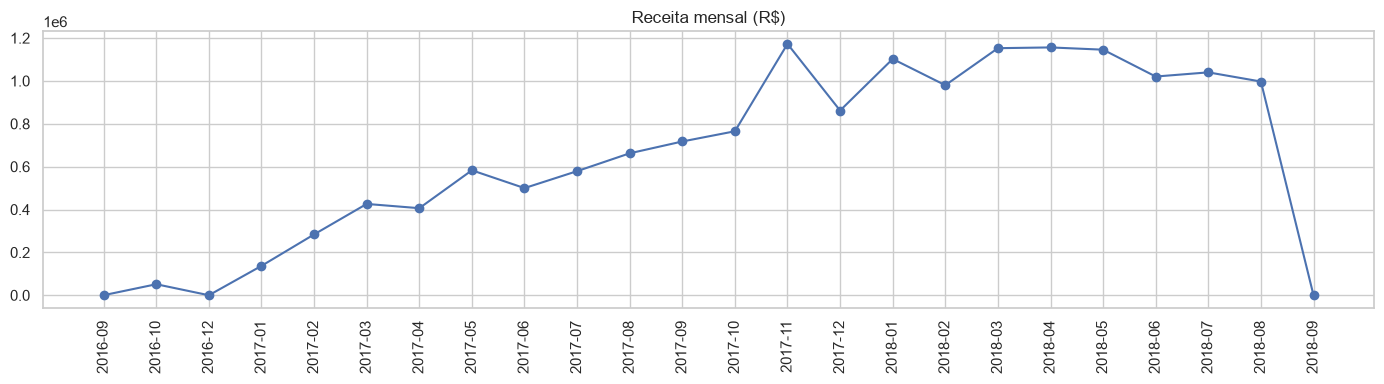

In [20]:
# Receita mensal
mensal = df_valido.groupby("ano_mes")["valor_total"].sum().reset_index()
mensal = mensal[mensal["valor_total"] > 0]
plt.figure(figsize=(14, 4))
plt.plot(mensal["ano_mes"], mensal["valor_total"], marker="o")
plt.xticks(rotation=90); plt.title("Receita mensal (R$)"); plt.tight_layout(); plt.show()

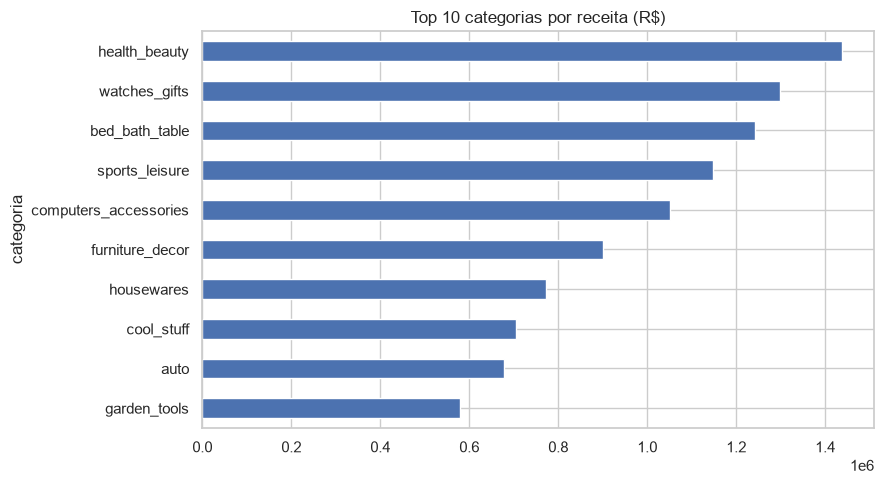

In [21]:
# Top 10 categorias por receita
top_cat = (df_valido.groupby("categoria")["valor_total"].sum()
           .sort_values(ascending=False).head(10))
top_cat.sort_values().plot(kind="barh", figsize=(9, 5), title="Top 10 categorias por receita (R$)")
plt.tight_layout(); plt.show()

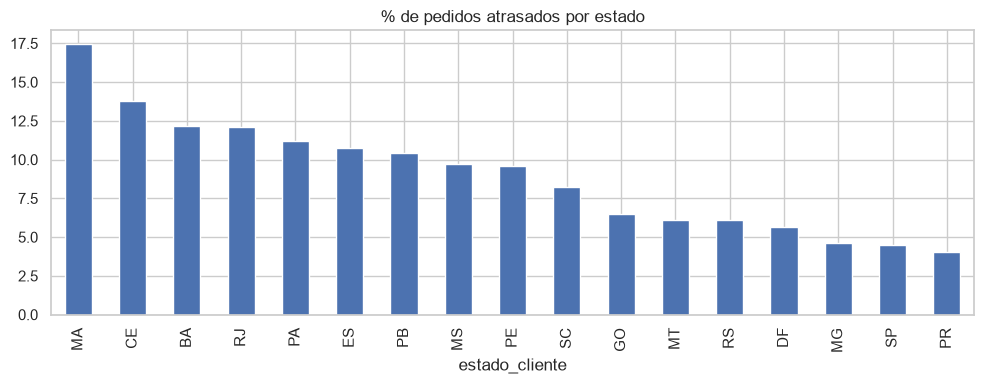

,pedidos,pct_atraso
estado_cliente,,
MA,716,0.17
CE,1277,0.14
BA,3256,0.12
RJ,12347,0.12
PA,946,0.11
ES,1994,0.11
PB,519,0.10
MS,700,0.10
PE,1590,0.10


In [22]:
# Atraso por estado do cliente (estados com pelo menos 500 pedidos)
est = pedidos.groupby("estado_cliente").agg(pedidos=("order_id", "count"), pct_atraso=("atrasou", "mean"))
est = est[est["pedidos"] >= 500].sort_values("pct_atraso", ascending=False)
(est["pct_atraso"] * 100).plot(kind="bar", figsize=(10, 4), title="% de pedidos atrasados por estado")
plt.tight_layout(); plt.show()
est

In [23]:
# Interpretação das métricas (números calculados a partir dos dados)
mes_top = mensal.loc[mensal["valor_total"].idxmax()]
cat_top = top_cat.index[0]
pior_estado = est.index[0]
melhor_estado = est.index[-1]

display(Markdown(f"""**Resumo das métricas:**

- A receita total (pedidos válidos) é de **R$ {fmt_d(receita_total)}**, em **{fmt_n(n_pedidos)} pedidos**, com ticket médio de R$ {fmt_d(ticket_medio)} por pedido.
- O mês de maior receita foi **{mes_top["ano_mes"]}** (R$ {fmt_d(mes_top["valor_total"])}), e a categoria líder em receita é **{cat_top}**.
- Entre os pedidos entregues, o prazo médio é de {fmt_d(tempo_medio, 1)} dias, a nota média é {fmt_d(nota_media)} e {fmt_p(pct_atraso)} chegaram atrasados.
- O atraso varia por região: entre os estados com pelo menos 500 pedidos, o maior percentual de atraso é em **{pior_estado}** ({fmt_p(est.iloc[0]["pct_atraso"])}) e o menor em **{melhor_estado}** ({fmt_p(est.iloc[-1]["pct_atraso"])})."""))

**Resumo das métricas:**

- A receita total (pedidos válidos) é de **R$ 15.738.905,00**, em **98.199 pedidos**, com ticket médio de R$ 160,28 por pedido.
- O mês de maior receita foi **2017-11** (R$ 1.172.578,00), e a categoria líder em receita é **health_beauty**.
- Entre os pedidos entregues, o prazo médio é de 12,5 dias, a nota média é 4,16 e 6,8% chegaram atrasados.
- O atraso varia por região: entre os estados com pelo menos 500 pedidos, o maior percentual de atraso é em **MA** (17,5%) e o menor em **PR** (4,0%).

## 8. Achado de negócio: atraso x satisfação

Hipótese: **pedidos entregues com atraso recebem notas piores**.

In [24]:
print(pedidos.groupby("atrasou")["nota_avaliacao"].agg(["mean", "count"]))

         mean  count
atrasou             
0.00     4.29  89448
1.00     2.27   6382


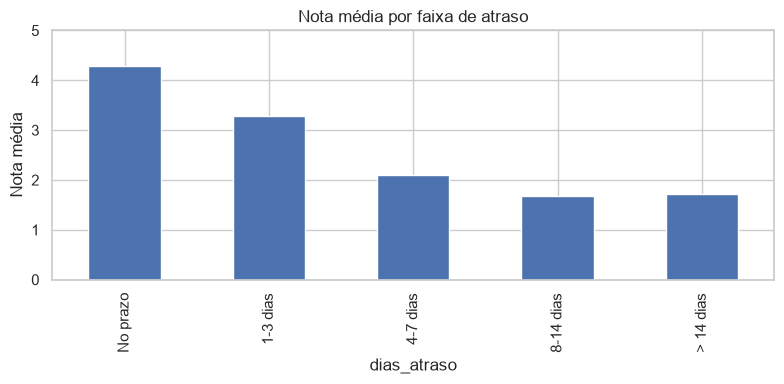

,mean,count
dias_atraso,,
No prazo,4.29,89448
1-3 dias,3.29,1852
4-7 dias,2.11,1748
8-14 dias,1.67,1447
> 14 dias,1.73,1335


In [25]:
faixas = pd.cut(pedidos["dias_atraso"],
                bins=[-999, 0, 3, 7, 14, 999],
                labels=["No prazo", "1-3 dias", "4-7 dias", "8-14 dias", "> 14 dias"])
nota_faixa = pedidos.groupby(faixas, observed=True)["nota_avaliacao"].agg(["mean", "count"])
nota_faixa["mean"].plot(kind="bar", figsize=(8, 4), title="Nota média por faixa de atraso")
plt.ylabel("Nota média"); plt.ylim(0, 5); plt.tight_layout(); plt.show()
nota_faixa

In [26]:
# Conclusão (números calculados a partir dos dados)
nota_prazo = nota_faixa.loc["No prazo", "mean"]
nota_13 = nota_faixa.loc["1-3 dias", "mean"]
nota_min = nota_faixa["mean"].min()
faixa_min = nota_faixa["mean"].idxmin()
pct_atr = pedidos["atrasou"].mean()
qtd_atr = int(pedidos["atrasou"].sum())

if nota_13 < nota_prazo:
    parte1 = (f"pedidos entregues no prazo têm nota média de {fmt_d(nota_prazo)}, enquanto um atraso de apenas 1 a 3 dias "
              f"reduz a nota para {fmt_d(nota_13)} (queda de {fmt_d(nota_prazo - nota_13)} pontos). "
              f"A menor nota média está na faixa de {faixa_min} ({fmt_d(nota_min)}).")
    if pct_atr < 0.2:
        parte2 = (f"Embora só {fmt_p(pct_atr)} dos pedidos entregues ({fmt_n(qtd_atr)}) tenham chegado atrasados, "
                  f"o impacto na satisfação é forte, o que indica que reduzir os atrasos deve ser prioridade para a operação logística.")
    else:
        parte2 = (f"{fmt_p(pct_atr)} dos pedidos entregues ({fmt_n(qtd_atr)}) chegaram atrasados, "
                  f"e o impacto na satisfação é forte, o que indica que reduzir os atrasos deve ser prioridade para a operação logística.")
else:
    parte1 = (f"pedidos entregues no prazo têm nota média de {fmt_d(nota_prazo)} e os atrasados de 1 a 3 dias, {fmt_d(nota_13)}: "
              f"a análise não evidencia queda de nota nessa faixa.")
    parte2 = f"{fmt_p(pct_atr)} dos pedidos entregues ({fmt_n(qtd_atr)}) chegaram atrasados."

display(Markdown(f"""**Conclusão:** {parte1} {parte2}

*Ressalva:* a análise mostra uma **associação** entre atraso e nota; ela não prova que o atraso seja a única causa da insatisfação."""))

**Conclusão:** pedidos entregues no prazo têm nota média de 4,29, enquanto um atraso de apenas 1 a 3 dias reduz a nota para 3,29 (queda de 1,00 pontos). A menor nota média está na faixa de 8-14 dias (1,67). Embora só 6,8% dos pedidos entregues (6.535) tenham chegado atrasados, o impacto na satisfação é forte, o que indica que reduzir os atrasos deve ser prioridade para a operação logística.

*Ressalva:* a análise mostra uma **associação** entre atraso e nota; ela não prova que o atraso seja a única causa da insatisfação.

## 9. Exportar tabelas de apoio (opcional)

In [27]:
os.makedirs("saida", exist_ok=True)
mensal.to_csv("saida/receita_mensal.csv", index=False)
nota_faixa.reset_index().to_csv("saida/nota_por_faixa_atraso.csv", index=False)
est.reset_index().to_csv("saida/atraso_por_estado.csv", index=False)